Imagine you work for google news and you want to group news articles by topic.
Or you work for a legal firm and you need to sift through thousands of pages of legal documents to find relevant ones.
This is where NLP can help.
We will want to:
- compile documents
- featurise them
- compare their features

Simple example:
- you have 2 documents:
  + Blue House
  + Red House
- Feature based on world count
  + Blue House -> red, blue, house -> (0,1,1)
  + Red House -> red, blue, house -> (1,0,1)

- A document represented as a vector of word counts is called a "Bag of Words"
  + Blue House -> (red, blue, house) -> (0,1,1)
  + Red House -> (red, blue, house) -> (1,0,1)
- You can use cosine similarity on the vector made to determine similarity
  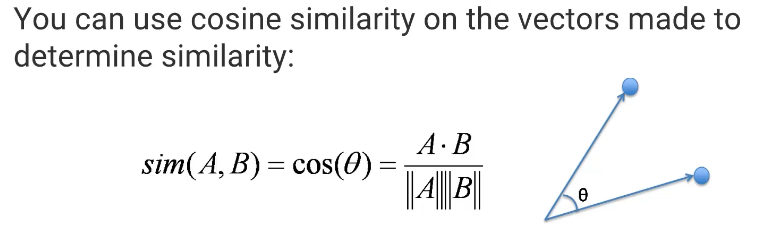

- We can improve on Bag of Words by adjusting word counts based on their frequency in corpus (the group of all the documents)
- We can use TF-IDF (Term Frequency - Inverse Document Frequency) 

- **Term Frequency** - Importance of the term within that document
  + TF(d,t) = Number of occurences of term t in document d
- **Inverse Document Frequency** - Importance of the term in the corpus
  + IDF(t) = log(D/t) where
    + D = total number of documents
    + t = number of documents with the term
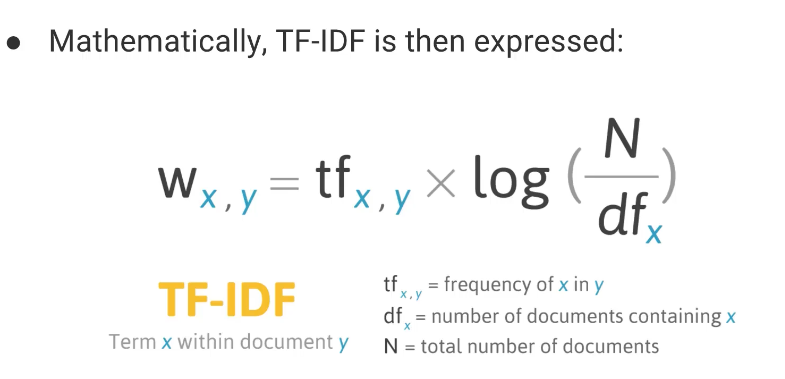

In [3]:
import nltk

In [4]:
#nltk.download_shell()
# download the dataset from uci dataset

In [5]:
# to build a spam detector with python
messages = [line.rstrip() for line in open('Refactored_Py_DS_ML_Bootcamp-master 2/20-Natural-Language-Processing/smsspamcollection/SMSSpamCollection')]

In [6]:
messages[:10]

['ham\tGo until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...',
 'ham\tOk lar... Joking wif u oni...',
 "spam\tFree entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's",
 'ham\tU dun say so early hor... U c already then say...',
 "ham\tNah I don't think he goes to usf, he lives around here though",
 "spam\tFreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv",
 'ham\tEven my brother is not like to speak with me. They treat me like aids patent.',
 "ham\tAs per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Callertune",
 'spam\tWINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Cl

In [7]:
print(len(messages))

5574


In [8]:
messages[50]

'ham\tWhat you thinked about me. First time you saw me in class.'

In [9]:
for mess_no, message in enumerate(messages[:10]):
    print(mess_no, message)
    print('\n')

0 ham	Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...


1 ham	Ok lar... Joking wif u oni...


2 spam	Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


3 ham	U dun say so early hor... U c already then say...


4 ham	Nah I don't think he goes to usf, he lives around here though


5 spam	FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv


6 ham	Even my brother is not like to speak with me. They treat me like aids patent.


7 ham	As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Callertune


8 spam	WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code 

In [10]:
messages[0]

'ham\tGo until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...'

In [11]:
import pandas as pd

In [12]:
messages = pd.read_csv('Refactored_Py_DS_ML_Bootcamp-master 2/20-Natural-Language-Processing/smsspamcollection/SMSSpamCollection', sep = '\t',
                       names = ['label','message'])

In [13]:
messages.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [14]:
# exploratory data analysis
messages.describe()

,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [15]:
messages.groupby('label').describe()

message                                                               
        count unique                                                top freq
label                                                                       
ham      4825   4516                             Sorry, I'll call later   30
spam      747    653  Please call our customer service representativ...    4

In [16]:
messages['length']=messages['message'].apply(len)

In [17]:
messages.head()

,label,message,length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

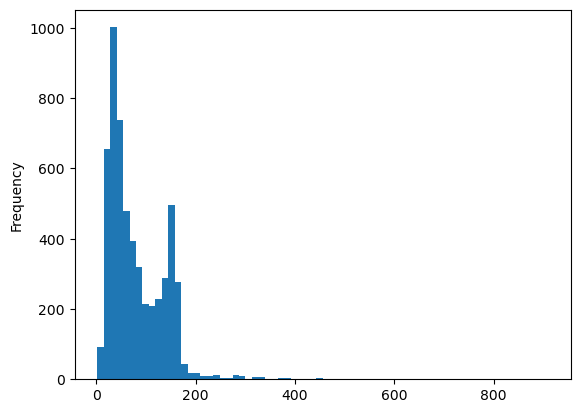

In [19]:
messages['length'].plot.hist(bins=70)
plt.show()

In [20]:
messages['length'].describe()

count    5572.000000
mean       80.489950
std        59.942907
min         2.000000
25%        36.000000
50%        62.000000
75%       122.000000
max       910.000000
Name: length, dtype: float64

In [21]:
messages[messages['length']==910]['message'].iloc[0]

"For me the love should start with attraction.i should feel that I need her every time around me.she should be the first thing which comes in my thoughts.I would start the day and end it with her.she should be there every time I dream.love will be then when my every breath has her name.my life should happen around her.my life will be named to her.I would cry for her.will give all my happiness and take all her sorrows.I will be ready to fight with anyone for her.I will be in love when I will be doing the craziest things for her.love will be when I don't have to proove anyone that my girl is the most beautiful lady on the whole planet.I will always be singing praises for her.love will be when I start up making chicken curry and end up makiing sambar.life will be the most beautiful then.will get every morning and thank god for the day because she is with me.I would like to say a lot..will tell later.."

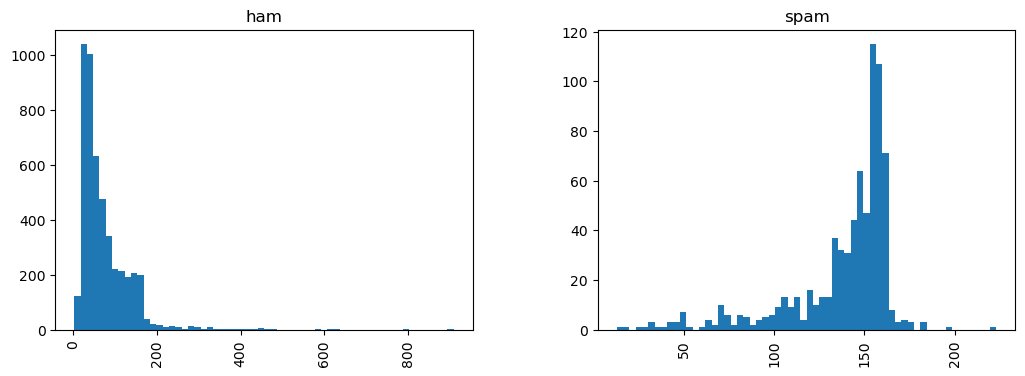

In [22]:
messages.hist(column='length', by = 'label', bins=60, figsize=(12,4))
plt.show()

In [23]:
import string

In [24]:
mess = 'Sample message! Notice: it has punctuation.'

In [25]:
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [26]:
#use list comprehension
nopunc = [c for c in mess if c not in string.punctuation]

In [27]:
nopunc

['S',
 'a',
 'm',
 'p',
 'l',
 'e',
 ' ',
 'm',
 'e',
 's',
 's',
 'a',
 'g',
 'e',
 ' ',
 'N',
 'o',
 't',
 'i',
 'c',
 'e',
 ' ',
 'i',
 't',
 ' ',
 'h',
 'a',
 's',
 ' ',
 'p',
 'u',
 'n',
 'c',
 't',
 'u',
 'a',
 't',
 'i',
 'o',
 'n']

In [28]:
from nltk.corpus import stopwords

In [29]:
stopwords.words('english')

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [30]:
nopunc = ''.join(nopunc)

In [31]:
nopunc

'Sample message Notice it has punctuation'

In [32]:
x = ['a','b','c','d']

In [33]:
x

['a', 'b', 'c', 'd']

In [34]:
''.join(x)

'abcd'

In [35]:
# explain how join works here. Just add the string at the beginning with the elements in x
'+++'.join(x)

'a+++b+++c+++d'

In [36]:
'_'.join(x)

'a_b_c_d'

In [37]:
nopunc.split()

['Sample', 'message', 'Notice', 'it', 'has', 'punctuation']

In [38]:
clean_mess = [word for word in nopunc.split() if word.lower() not in stopwords.words('english')]

In [39]:
clean_mess

['Sample', 'message', 'Notice', 'punctuation']

In [40]:
# now apply to the whole dataframe
def text_process(mess):
    """
    1. remove punctuation
    2. remove stop words
    3. return list of clean text words
    """
    nopunc = [char for char in mess if char not in string.punctuation]
    nopunc = ''.join(nopunc)
    return [word for word in nopunc.split() if word.lower() not in stopwords.words('english')]
    

In [41]:
messages.head()

,label,message,length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [42]:
messages['message'].head().apply(text_process)

0    [Go, jurong, point, crazy, Available, bugis, n...
1                       [Ok, lar, Joking, wif, u, oni]
2    [Free, entry, 2, wkly, comp, win, FA, Cup, fin...
3        [U, dun, say, early, hor, U, c, already, say]
4    [Nah, dont, think, goes, usf, lives, around, t...
Name: message, dtype: object

In [43]:
# please look at the lecture notebook - it's explained detailed - now we just vectorisation the data
from sklearn.feature_extraction.text import CountVectorizer

In [44]:
bow_transformer = CountVectorizer(analyzer=text_process).fit(messages['message'])

In [45]:
print(len(bow_transformer.vocabulary_))

11425


In [46]:
mess4 = messages['message'][3]

In [47]:
print(mess4)

U dun say so early hor... U c already then say...


In [48]:
bow4 = bow_transformer.transform([mess4])

In [49]:
print(bow4)

  (0, 4068)	2
  (0, 4629)	1
  (0, 5261)	1
  (0, 6204)	1
  (0, 6222)	1
  (0, 7186)	1
  (0, 9554)	2


In [50]:
print(bow4.shape)

(1, 11425)


In [51]:
# check which words appear twice
bow_transformer.get_feature_names_out()[4068]

'U'

In [52]:
bow_transformer.get_feature_names_out()[9554]

'say'

In [53]:
messages_bow = bow_transformer.transform(messages['message'])

In [54]:
print('Shape of sparse Matrix: ', messages_bow.shape)

Shape of sparse Matrix:  (5572, 11425)


In [55]:
# the amount of non-zero columns
messages_bow.nnz

50548

In [56]:
sparsity = (100.0 * messages_bow.nnz / (messages_bow.shape[0] * messages_bow.shape[1]))
('sparsity: {}'.format(round(sparsity)))

'sparsity: 0'

In [57]:
sparsity = (100.0 * messages_bow.nnz / (messages_bow.shape[0] * messages_bow.shape[1]))
('sparsity: {}'.format(sparsity))

'sparsity: 0.07940295412668218'

In [58]:
from sklearn.feature_extraction.text import TfidfTransformer
# term frequency inverse document frequency

In [59]:
tfidf_transformer = TfidfTransformer().fit(messages_bow)

In [60]:
tfidf4 = tfidf_transformer.transform(bow4)

In [61]:
print(tfidf4)

  (0, 4068)	0.40832589933384067
  (0, 4629)	0.26619801906087187
  (0, 5261)	0.29729957405868723
  (0, 6204)	0.29953799723697416
  (0, 6222)	0.3187216892949149
  (0, 7186)	0.4389365653379857
  (0, 9554)	0.5385626262927564


In [62]:
# check frequency of the word "university"
tfidf_transformer.idf_[bow_transformer.vocabulary_['university']]

8.527076498901426

In [63]:
messages_tfidf = tfidf_transformer.transform(messages_bow)

In [126]:
from sklearn.naive_bayes import MultinomialNB

In [128]:
spam_detect_model = MultinomialNB().fit(messages_tfidf, messages['label'])

In [130]:
spam_detect_model.predict(tfidf4)

array(['ham'], dtype='<U4')

In [132]:
messages['label'][3]

'ham'

In [136]:
all_spread = spam_detect_model.predict(messages_tfidf)

In [138]:
all_spread

array(['ham', 'ham', 'spam', ..., 'ham', 'ham', 'ham'], dtype='<U4')

In [140]:
# to check how well it functions use train test split
from sklearn.model_selection import train_test_split

In [142]:
msg_train, msg_test, label_train, label_test = train_test_split(messages['message'], messages['label'], test_size = 0.3)

In [144]:
msg_train

4407    As one of our registered subscribers u can ent...
1091    WIN URGENT! Your mobile number has been awarde...
1184               Am i that much bad to avoid like this?
4718    K will do, addie &amp; I are doing some art so...
3972    Free video camera phones with Half Price line ...
                              ...                        
4269                     Hey so whats the plan this sat? 
4843        Awesome, that gonna be soon or later tonight?
586     Tell them u have a headache and just want to u...
2957                           Yes there were many sweets
2761           I dont thnk its a wrong calling between us
Name: message, Length: 3900, dtype: object

In [146]:
# we can do the whole process as we did before but now with train model
# but in real world data we don't have to do that as sklearn has a datapipeline packet
from sklearn.pipeline import Pipeline


In [148]:
pipeline = Pipeline([
    ('bow', CountVectorizer(analyzer=text_process)),
    ('tfidf', TfidfTransformer()),
    ('classifier',MultinomialNB())
])
# pass the list of everything you want to do 

In [150]:
pipeline.fit(msg_train, label_train)

Pipeline(steps=[('bow',
                 CountVectorizer(analyzer=<function text_process at 0x17891d760>)),
                ('tfidf', TfidfTransformer()),
                ('classifier', MultinomialNB())])

In [152]:
prediction = pipeline.predict(msg_test)

In [154]:
from sklearn.metrics import classification_report

In [160]:
print(classification_report(label_test, prediction))

              precision    recall  f1-score   support

         ham       0.96      1.00      0.98      1445
        spam       1.00      0.71      0.83       227

    accuracy                           0.96      1672
   macro avg       0.98      0.85      0.90      1672
weighted avg       0.96      0.96      0.96      1672



In [162]:
# if you want to use random forest classifier
from sklearn.ensemble import RandomForestClassifier

In [164]:
# now using random forest to classify in pipeline
pipeline_2 = Pipeline([
    ('bow', CountVectorizer(analyzer=text_process)),
    ('tfidf', TfidfTransformer()),
    ('classifier',RandomForestClassifier())
])

In [166]:
pipeline_2.fit(msg_train, label_train)

Pipeline(steps=[('bow',
                 CountVectorizer(analyzer=<function text_process at 0x17891d760>)),
                ('tfidf', TfidfTransformer()),
                ('classifier', RandomForestClassifier())])

In [168]:
predictions = pipeline_2.predict(msg_test)

In [170]:
print(classification_report(label_test, predictions))

              precision    recall  f1-score   support

         ham       0.97      1.00      0.98      1445
        spam       0.99      0.80      0.89       227

    accuracy                           0.97      1672
   macro avg       0.98      0.90      0.94      1672
weighted avg       0.97      0.97      0.97      1672

